# Segmentasi Pelanggan UMKM Roti & Kopi (Kasus 05)

**Tujuan:** mengelompokkan ±10.000 anggota aplikasi member menjadi segmen yang masuk akal secara bisnis,
memberi nama dan profil setiap segmen, menyarankan satu tindakan promo per segmen, dan menyimpan model
yang dapat menempatkan **pelanggan baru** ke salah satu segmen.

Ini masalah *unsupervised learning* (tidak ada label jawaban), jadi kualitas hasil dinilai dari:
1. ukuran pemisahan cluster (*silhouette*, Davies-Bouldin) untuk memilih jumlah segmen,
2. stabilitas hasil, dan
3. apakah profil setiap segmen **bisa dibaca dan ditindaklanjuti** oleh pemilik usaha.

**Alur notebook:** audit data → pembersihan → eksplorasi → rekayasa fitur → baseline K-Means → perbaikan →
pemilihan k → profil segmen → rekomendasi → simpan model + uji prediksi pelanggan baru.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)

from src import features as ft, segmen as seg

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
SEED = 42

# Gaya grafik: permukaan terang, grid samar, teks netral (bukan warna seri)
TEKS, TEKS2, GRID, PERMUKAAN = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": PERMUKAAN, "axes.facecolor": PERMUKAAN, "savefig.facecolor": PERMUKAAN,
    "axes.edgecolor": GRID, "axes.labelcolor": TEKS2, "xtick.color": TEKS2, "ytick.color": TEKS2,
    "text.color": TEKS, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "lines.linewidth": 2,
})
SERI = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # slot kategori tetap 1-4
NETRAL = "#c9c8c1"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
URUTAN_SEGMEN = list(seg.INFO_SEGMEN)                       # warna mengikuti entitas, bukan urutan
WARNA_SEGMEN = {n: seg.INFO_SEGMEN[n]["warna"] for n in URUTAN_SEGMEN}

## 1. Audit data mentah

Brief menyebut data "diekspor apa adanya dan belum diperiksa". Jadi langkah pertama adalah mengukur
masalahnya sebelum memutuskan cara membersihkan.

In [2]:
raw = pd.read_csv(ROOT / "kasus" / "05-segmentasi-umkm" / "data" / "raw.csv")
print("Ukuran:", raw.shape)
raw.head()

Ukuran: (10150, 12)


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
0,PLG-08573,2025-10-10,27.00,Cidadap,shopeefood,ewallet,roti,31,1791100,7,15,4.70
1,PLG-06930,2026-05-19,33.00,Sukajadi,toko,transfer,kopi,15,Rp 365.100,10,83,4.70
2,PLG-05499,2024-02-28,31.00,Cidadap,toko,qris,roti,30,1603900,2,26,4.30
3,PLG-06747,2025-11-22,99.00,Coblong,grabfood,ewallet,kopi,12,360200,7,72,4.20
4,PLG-02367,2025-07-31,32.00,Bandung Wetan,gofood,ewallet,kopi,3,582400,13,10,4.50


In [3]:
audit = pd.DataFrame({
    "tipe": raw.dtypes.astype(str),
    "kosong": raw.isna().sum(),
    "% kosong": (raw.isna().mean() * 100).round(2),
    "nilai unik": raw.nunique(),
})
audit

,tipe,kosong,% kosong,nilai unik
id_pelanggan,str,0,0.00,10000
tanggal_daftar,str,0,0.00,870
umur,float64,208,2.05,47
kecamatan,str,0,0.00,15
channel_utama,str,0,0.00,4
metode_bayar,str,0,0.00,4
kategori_favorit,str,0,0.00,4
jumlah_transaksi_6bln,int64,0,0.00,53
total_belanja_rp,str,0,0.00,7345
hari_sejak_transaksi_terakhir,int64,0,0.00,209


In [4]:
print("Baris duplikat persis   :", raw.duplicated().sum())
print("ID duplikat             :", raw["id_pelanggan"].duplicated().sum(),
      "| ID unik:", raw["id_pelanggan"].nunique())

# Duplikat yang TIDAK persis: kolom apa yang berbeda?
grup = raw[raw["id_pelanggan"].duplicated(keep=False)].drop_duplicates()
beda = (grup.groupby("id_pelanggan").nunique() > 1).sum()
print("Kolom yang berbeda pada ID ganda (bukan duplikat persis):")
print(beda[beda > 0])
grup.sort_values("id_pelanggan").head(6)

Baris duplikat persis   : 90
ID duplikat             : 150 | ID unik: 10000
Kolom yang berbeda pada ID ganda (bukan duplikat persis):
hari_sejak_transaksi_terakhir    60
dtype: int64


,id_pelanggan,tanggal_daftar,umur,kecamatan,channel_utama,metode_bayar,kategori_favorit,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,rating_rata
3145,PLG-00026,2025-01-21,17.00,Cidadap,grabfood,qris,kue_ulang_tahun,15,622900,2,87,4.40
95,PLG-00047,2026-04-09,26.00,Coblong,gofood,qris,kopi,2,75200,121,73,3.70
1255,PLG-00079,2025-12-21,45.00,Sukajadi,toko,transfer,roti,21,1003600,11,16,4.20
8828,PLG-00079,2025-12-21,45.00,Sukajadi,toko,transfer,roti,21,1003600,10,16,4.20
3655,PLG-00116,2026-04-05,23.00,Arcamanik,grabfood,tunai,kue_ulang_tahun,22,1014600,9,23,4.50
1559,PLG-00264,2025-10-18,25.00,Sumur Bandung,gofood,transfer,paket_snack,9,222600,12,74,4.60


In [5]:
tb = raw["total_belanja_rp"].astype(str)
print("total_belanja_rp berformat teks 'Rp x.xxx':", tb.str.startswith("Rp").sum(), "baris")
print(tb[tb.str.startswith("Rp")].head(3).tolist())

print("\nPenulisan kecamatan (seharusnya 10):")
print(raw["kecamatan"].map(repr).value_counts())

total_belanja_rp berformat teks 'Rp x.xxx': 507 baris
['Rp 365.100', 'Rp 446.400', 'Rp 1.044.300']

Penulisan kecamatan (seharusnya 10):
kecamatan
'Buahbatu'             1046
'Cidadap'              1029
'Sumur Bandung'        1002
'Arcamanik'            1000
'Sukajadi'              989
'Bandung Wetan'         984
'Lengkong'              976
'Antapani'              976
'Coblong'               951
'Cibeunying Kidul'      943
'SUKAJADI'               68
'Bdg Wetan'              57
'Buah Batu'              47
'coblong'                46
'Cibeunying Kidul '      36
Name: count, dtype: int64


In [6]:
print("Umur di luar 15-80 tahun:")
print(raw.loc[(raw["umur"] < 15) | (raw["umur"] > 80), "umur"].value_counts().sort_index())
print("\nKategori lain (sudah konsisten):")
for c in ["channel_utama", "metode_bayar", "kategori_favorit"]:
    print(c, dict(raw[c].value_counts()))

Umur di luar 15-80 tahun:
umur
0.00      27
1.00      20
99.00     25
120.00    28
Name: count, dtype: int64

Kategori lain (sudah konsisten):
channel_utama {'toko': np.int64(4666), 'gofood': np.int64(2174), 'shopeefood': np.int64(1705), 'grabfood': np.int64(1605)}
metode_bayar {'qris': np.int64(4567), 'tunai': np.int64(2546), 'ewallet': np.int64(1975), 'transfer': np.int64(1062)}
kategori_favorit {'kopi': np.int64(4175), 'roti': np.int64(3488), 'kue_ulang_tahun': np.int64(1257), 'paket_snack': np.int64(1230)}


**Temuan audit**

| Masalah | Dampak | Keputusan |
|---|---|---|
| `total_belanja_rp` campuran angka & teks `Rp 1.044.300` | kolom terbaca sebagai teks | hapus `Rp` dan titik ribuan, lalu ubah ke angka |
| 150 ID ganda (90 duplikat persis, 60 hanya beda recency 1 hari) | pelanggan terhitung dua kali | simpan **1 baris per ID**, ambil recency terkecil (ekspor terbaru) |
| Kecamatan ditulis beda (`SUKAJADI`, `coblong`, `Buah Batu`, `Bdg Wetan`, spasi di belakang) | satu kecamatan terpecah jadi beberapa | petakan ke 10 nama baku |
| Umur 0, 1, 99, 120 (±100 baris) + 208 kosong | nilai *default* sistem, bukan umur asli | jadikan kosong lalu isi median; umur **tidak** dipakai untuk clustering |
| `rating_rata` kosong ±8% | pelanggan tidak pernah memberi rating | tandai `pernah_rating`; rating hanya untuk profil |

## 2. Pembersihan

In [7]:
df, log_bersih = ft.bersihkan(raw)
pd.Series(log_bersih, name="jumlah")

baris_awal                        10150
kecamatan_dirapikan                 254
duplikat_persis                      90
baris_setelah_dedup               10000
umur_tidak_wajar                    100
umur_kosong                         300
rating_kosong                       800
recency_lebih_dari_masa_member      283
recency_lebih_dari_180               64
baris_akhir                       10000
Name: jumlah, dtype: int64

In [8]:
print("Kecamatan setelah dirapikan:", df["kecamatan"].nunique())
print(df["kecamatan"].value_counts())
df[["umur", "jumlah_transaksi_6bln", "total_belanja_rp", "hari_sejak_transaksi_terakhir",
    "persen_pakai_promo", "rating_rata", "masa_member_hari"]].describe().T

Kecamatan setelah dirapikan: 10
kecamatan
Buahbatu            1077
Sukajadi            1037
Bandung Wetan       1024
Cidadap             1018
Sumur Bandung        989
Arcamanik            984
Coblong              979
Antapani             968
Cibeunying Kidul     964
Lengkong             960
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
umur,"10,000.00",28.87,7.69,16.00,23.00,28.00,34.00,59.00
jumlah_transaksi_6bln,"10,000.00",12.54,11.64,1.00,3.00,8.00,20.00,56.00
total_belanja_rp,"10,000.00","693,710.74","648,750.92","11,900.00","152,200.00","425,050.00","1,145,325.00","3,424,200.00"
hari_sejak_transaksi_terakhir,"10,000.00",41.76,49.35,0.00,6.00,15.00,75.00,225.00
persen_pakai_promo,"10,000.00",38.48,28.02,0.00,16.00,28.00,65.00,100.00
rating_rata,"9,200.00",4.15,0.52,2.00,3.80,4.20,4.50,5.00
masa_member_hari,"10,000.00",463.26,250.82,30.00,249.00,461.00,680.00,899.00


**Inkonsistensi logika yang ditandai (tidak dihapus)**

- `recency_lebih_dari_masa_member`: ±280 anggota punya transaksi terakhir *sebelum* tanggal daftar. Kemungkinan
  besar `tanggal_daftar` tercatat ulang (misalnya instal ulang aplikasi). Kolom perilaku mereka tetap wajar,
  dan `tanggal_daftar` tidak dipakai di model, jadi baris **dipertahankan** tetapi diberi *flag*.
- `recency_lebih_dari_180`: 64 baris recency > 180 hari padahal jendela datanya 6 bulan. Nilainya
  **dipotong (clip) ke 180** di tahap fitur.
- Sekitar 2.000 anggota mendaftar kurang dari 6 bulan lalu, sehingga jumlah transaksinya mungkin belum "penuh".
  Ini dicek setelah clustering (bagian 8).

## 3. Eksplorasi singkat

Skewness (|>1| = sangat miring):
jumlah_transaksi_6bln            1.01
total_belanja_rp                 1.02
hari_sejak_transaksi_terakhir    1.20
persen_pakai_promo               0.68
rating_rata                     -0.42
umur                             0.46
basket_rp                        2.42
dtype: float64


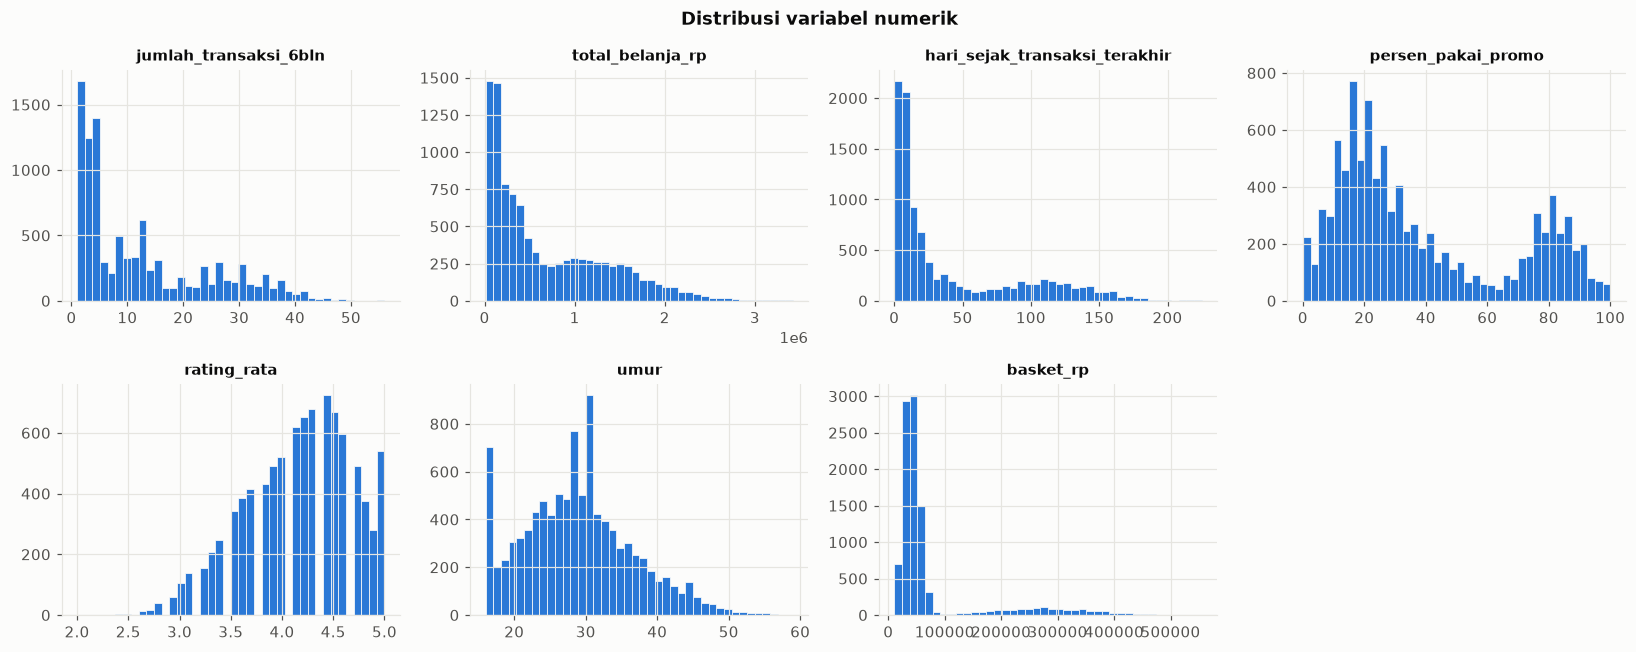

In [9]:
num = ["jumlah_transaksi_6bln", "total_belanja_rp", "hari_sejak_transaksi_terakhir",
       "persen_pakai_promo", "rating_rata", "umur"]
df["basket_rp"] = df["total_belanja_rp"] / df["jumlah_transaksi_6bln"]
print("Skewness (|>1| = sangat miring):")
print(df[num + ["basket_rp"]].skew().round(2))

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.flat, num + ["basket_rp"]):
    ax.hist(df[c].dropna(), bins=40, color=SERI[0], edgecolor=PERMUKAAN, linewidth=0.5)
    ax.set_title(c, fontsize=10)
axes.flat[-1].axis("off")
fig.suptitle("Distribusi variabel numerik", fontweight="bold")
plt.tight_layout(); plt.show()

Recency, frekuensi, total belanja, dan nilai per transaksi (*basket*) **sangat miring ke kanan**. K-Means memakai
jarak Euclidean, jadi segelintir pelanggan bernilai ekstrem bisa "menarik" centroid. Solusinya:
**transformasi log** lalu standardisasi.

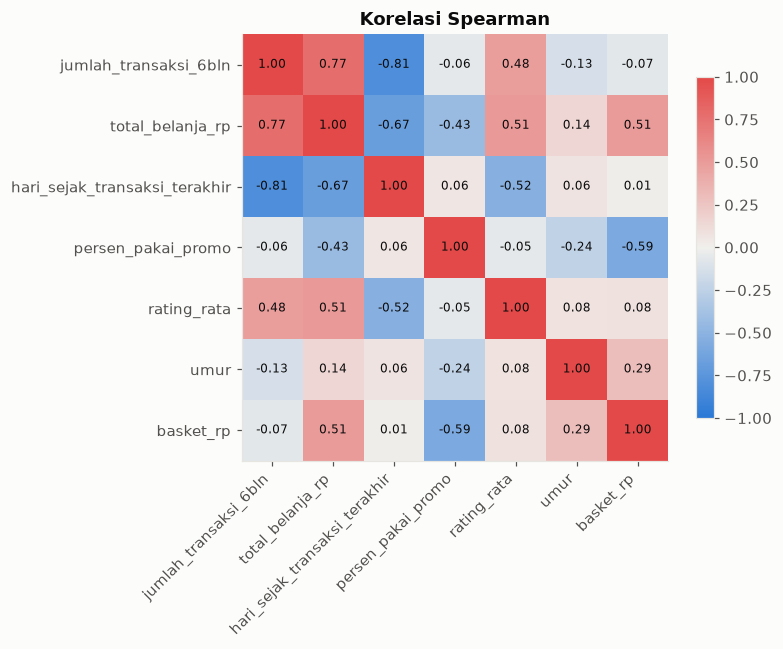

In [10]:
corr = df[num + ["basket_rp"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=TEKS)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Korelasi Spearman")
plt.tight_layout(); plt.show()

In [11]:
print("Median per kategori favorit:")
display(df.groupby("kategori_favorit")[["basket_rp", "jumlah_transaksi_6bln", "persen_pakai_promo", "umur"]].median())
print("Median per channel:")
display(df.groupby("channel_utama")[["basket_rp", "jumlah_transaksi_6bln", "persen_pakai_promo"]].median())

Median per kategori favorit:


,basket_rp,jumlah_transaksi_6bln,persen_pakai_promo,umur
kategori_favorit,,,,
kopi,"41,150.00",12.00,30.00,27.00
kue_ulang_tahun,"135,733.33",4.00,18.00,32.00
paket_snack,"144,858.33",5.00,18.00,33.00
roti,"40,200.00",10.00,34.00,28.00


Median per channel:


,basket_rp,jumlah_transaksi_6bln,persen_pakai_promo
channel_utama,,,
gofood,"39,175.96",8.00,40.00
grabfood,"40,579.17",7.00,37.00
shopeefood,"38,745.45",7.00,43.00
toko,"47,644.00",11.00,22.00


**Insight eksplorasi**
- Frekuensi berkorelasi kuat **negatif** dengan recency (−0,8): pelanggan yang sering datang juga baru saja datang.
- Total belanja ≈ frekuensi × basket, sehingga cukup memakai frekuensi dan basket.
- Pembeli **kue ulang tahun / paket snack** punya basket ±3× lebih besar tetapi frekuensinya rendah: pola berbeda.
- Pengguna **ojol** memakai promo jauh lebih sering daripada pembeli di toko.

## 4. Rekayasa fitur & praproses

Fitur clustering hanya memakai **perilaku belanja**, karena promo seharusnya ditargetkan berdasarkan perilaku:

| Fitur | Dasar | Transformasi |
|---|---|---|
| `recency_log` | hari sejak transaksi terakhir (clip 0-180) | log1p |
| `frekuensi_log` | jumlah transaksi 6 bulan | log1p |
| `basket_log` | total belanja ÷ jumlah transaksi | log1p |
| `persen_pakai_promo` | 0-100 | tanpa log (tidak miring) |

Lalu semuanya di-**StandardScaler** agar setiap fitur berbobot setara.

**Yang sengaja tidak dimasukkan:**
- `total_belanja_rp`: redundan (= frekuensi × basket).
- Kategori (channel, kategori favorit, metode bayar, kecamatan): *one-hot* membuat jarak K-Means bias ke variabel
  biner. Variabel ini dipakai untuk **membaca profil** segmen.
- `umur`, `rating_rata`: banyak nilai bermasalah/kosong, dan secara bisnis lebih tepat untuk profil.

In [12]:
fitur = ft.PembuatFitur().fit_transform(df[ft.KOLOM_INPUT])
fitur.describe().T

,count,mean,std,min,25%,50%,75%,max
recency_log,"10,000.00",2.94,1.41,0.00,1.95,2.77,4.33,5.20
frekuensi_log,"10,000.00",2.21,0.92,0.69,1.39,2.20,3.04,4.04
basket_log,"10,000.00",10.86,0.76,9.26,10.42,10.67,10.95,13.23
persen_pakai_promo,"10,000.00",38.48,28.02,0.00,16.00,28.00,65.00,100.00


## 5. Baseline wajib: K-Means

Baseline paling sederhana: K-Means pada RFM mentah (recency, frekuensi, total belanja) yang hanya di-standardisasi.
Kita laporkan **silhouette** (semakin tinggi semakin baik), **Davies-Bouldin** (semakin rendah semakin baik), dan
**inertia** (metode *elbow*) untuk k = 2-10.

In [13]:
def evaluasi_k(X, ks=range(2, 11)):
    hasil = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        hasil.append({"k": k, "silhouette": silhouette_score(X, km.labels_),
                      "davies_bouldin": davies_bouldin_score(X, km.labels_), "inertia": km.inertia_})
    return pd.DataFrame(hasil).set_index("k")

X_baseline = StandardScaler().fit_transform(
    df[["hari_sejak_transaksi_terakhir", "jumlah_transaksi_6bln", "total_belanja_rp"]])
hasil_baseline = evaluasi_k(X_baseline)
hasil_baseline

,silhouette,davies_bouldin,inertia
k,,,
2,0.48,0.81,"14,733.98"
3,0.54,0.66,"6,995.31"
4,0.55,0.64,"5,065.59"
5,0.53,0.69,"3,856.50"
6,0.49,0.71,"3,077.32"
7,0.47,0.75,"2,618.95"
8,0.46,0.76,"2,234.20"
9,0.41,0.82,"1,968.99"
10,0.40,0.80,"1,753.43"


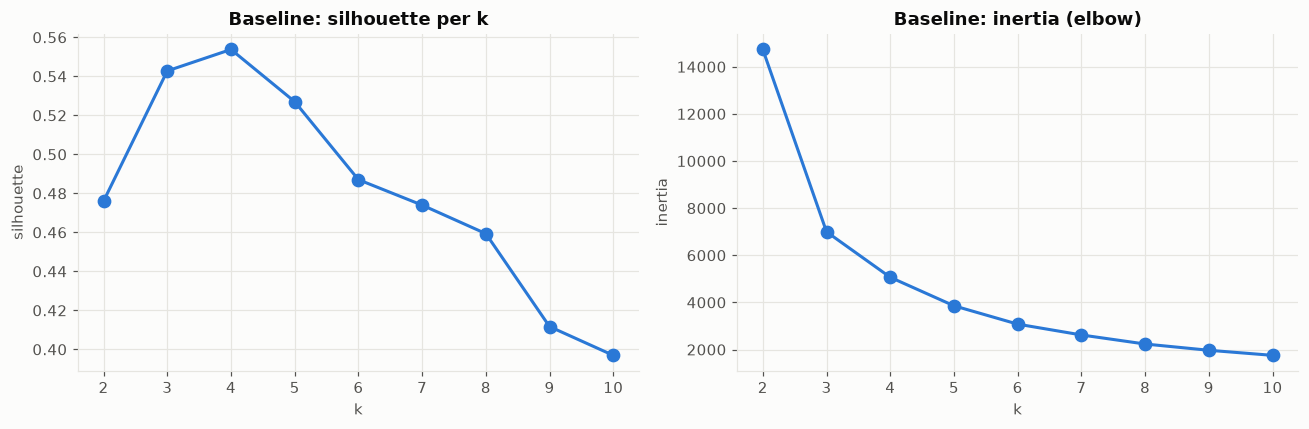

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hasil_baseline.index, hasil_baseline["silhouette"], marker="o", markersize=8, color=SERI[0])
axes[0].set(title="Baseline: silhouette per k", xlabel="k", ylabel="silhouette")
axes[1].plot(hasil_baseline.index, hasil_baseline["inertia"], marker="o", markersize=8, color=SERI[0])
axes[1].set(title="Baseline: inertia (elbow)", xlabel="k", ylabel="inertia")
plt.tight_layout(); plt.show()

## 6. Perbaikan

Tiga hal yang dicoba:
1. **Transformasi log** untuk variabel miring.
2. **Kombinasi fitur**: menambah *basket* dan *persen promo*, dua dimensi yang paling relevan untuk keputusan promo.
3. **Algoritma lain**: Gaussian Mixture Model dan Agglomerative (Ward) sebagai pembanding.

In [15]:
def matriks(cols, log_cols):
    X = df[cols].copy()
    X[R] = X[R].clip(upper=ft.BATAS_RECENCY)
    for c in log_cols:
        X[c] = np.log1p(X[c])
    return StandardScaler().fit_transform(X)

R, F, M, B, P = ("hari_sejak_transaksi_terakhir", "jumlah_transaksi_6bln", "total_belanja_rp",
                 "basket_rp", "persen_pakai_promo")
skenario = {
    "A. RFM mentah (baseline)": ([R, F, M], []),
    "B. RFM + log": ([R, F, M], [R, F, M]),
    "C. log R,F,Basket + Promo (dipilih)": ([R, F, B, P], [R, F, B]),
    "D. log R,F,M,Basket + Promo": ([R, F, M, B, P], [R, F, M, B]),
}
tabel_sil = {}
for nama, (cols, logc) in skenario.items():
    tabel_sil[nama] = evaluasi_k(matriks(cols, logc))["silhouette"]
tabel_sil = pd.DataFrame(tabel_sil)
tabel_sil.style.format("{:.3f}").highlight_max(axis=None, color="#cfe3fa")

,A. RFM mentah (baseline),B. RFM + log,"C. log R,F,Basket + Promo (dipilih)","D. log R,F,M,Basket + Promo"
k,,,,
2,0.476,0.521,0.428,0.409
3,0.544,0.482,0.505,0.480
4,0.555,0.522,0.613,0.604
5,0.528,0.519,0.536,0.505
6,0.487,0.458,0.425,0.419
7,0.476,0.446,0.385,0.362
8,0.460,0.406,0.363,0.351
9,0.411,0.387,0.366,0.334
10,0.398,0.366,0.285,0.284


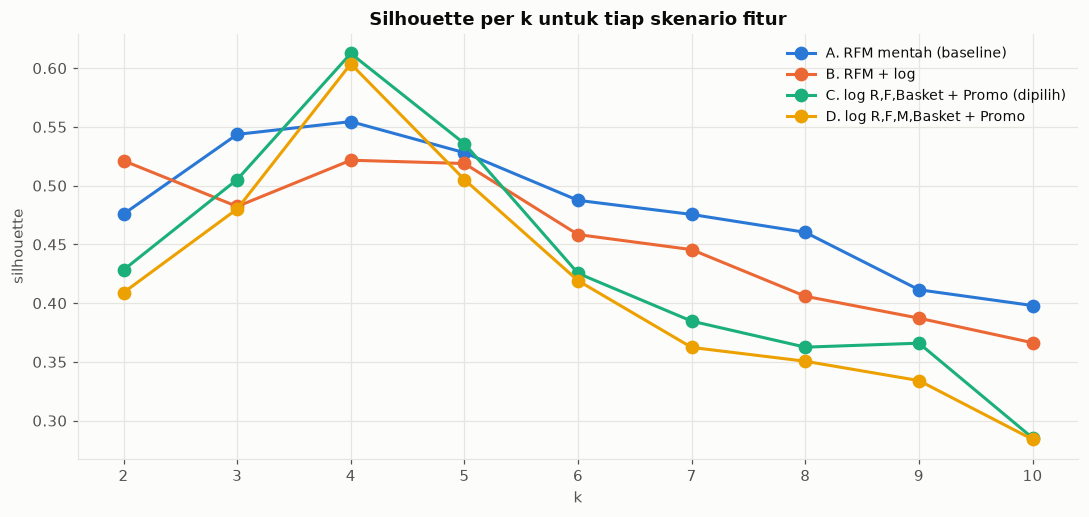

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for warna, nama in zip(SERI, tabel_sil.columns):
    ax.plot(tabel_sil.index, tabel_sil[nama], marker="o", markersize=8, color=warna, label=nama)
ax.set(title="Silhouette per k untuk tiap skenario fitur", xlabel="k", ylabel="silhouette")
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout(); plt.show()

In [17]:
X = ft.PembuatFitur().fit_transform(df[ft.KOLOM_INPUT])
X = StandardScaler().fit_transform(X)

rng = np.random.RandomState(SEED)
idx = rng.choice(len(X), 4000, replace=False)   # Ward butuh memori O(n^2): pakai sampel
banding = []
for k in [3, 4, 5]:
    km = KMeans(k, n_init=10, random_state=SEED).fit_predict(X)
    gm = GaussianMixture(k, n_init=3, random_state=SEED).fit(X).predict(X)
    ag = AgglomerativeClustering(k, linkage="ward").fit_predict(X[idx])
    banding += [
        {"k": k, "algoritma": "K-Means", "silhouette": silhouette_score(X, km), "davies_bouldin": davies_bouldin_score(X, km)},
        {"k": k, "algoritma": "GMM", "silhouette": silhouette_score(X, gm), "davies_bouldin": davies_bouldin_score(X, gm)},
        {"k": k, "algoritma": "Agglomerative (sampel 4.000)", "silhouette": silhouette_score(X[idx], ag), "davies_bouldin": davies_bouldin_score(X[idx], ag)},
    ]
pd.DataFrame(banding).pivot(index="algoritma", columns="k", values=["silhouette", "davies_bouldin"]).round(3)

silhouette           davies_bouldin          
k                                     3    4    5              3    4    5
algoritma                                                                 
Agglomerative (sampel 4.000)       0.50 0.61 0.55           0.76 0.54 0.73
GMM                                0.51 0.61 0.59           0.75 0.55 1.16
K-Means                            0.51 0.61 0.54           0.75 0.55 0.77

**Hasil perbaikan**
- Log + fitur **basket & promo** (skenario C) menaikkan silhouette terbaik dari ±0,55 (baseline) menjadi **±0,61**
  pada **k = 4**, dengan Davies-Bouldin terendah (±0,55).
- GMM dan Agglomerative menghasilkan skor hampir sama di k = 4. Artinya struktur 4 kelompok ini nyata di data,
  bukan kebetulan dari algoritma tertentu. **K-Means dipilih** karena paling sederhana, cepat, dan mudah memprediksi
  pelanggan baru (cukup cari centroid terdekat).

## 7. Memilih k = 4: skor, stabilitas, dan keterbacaan

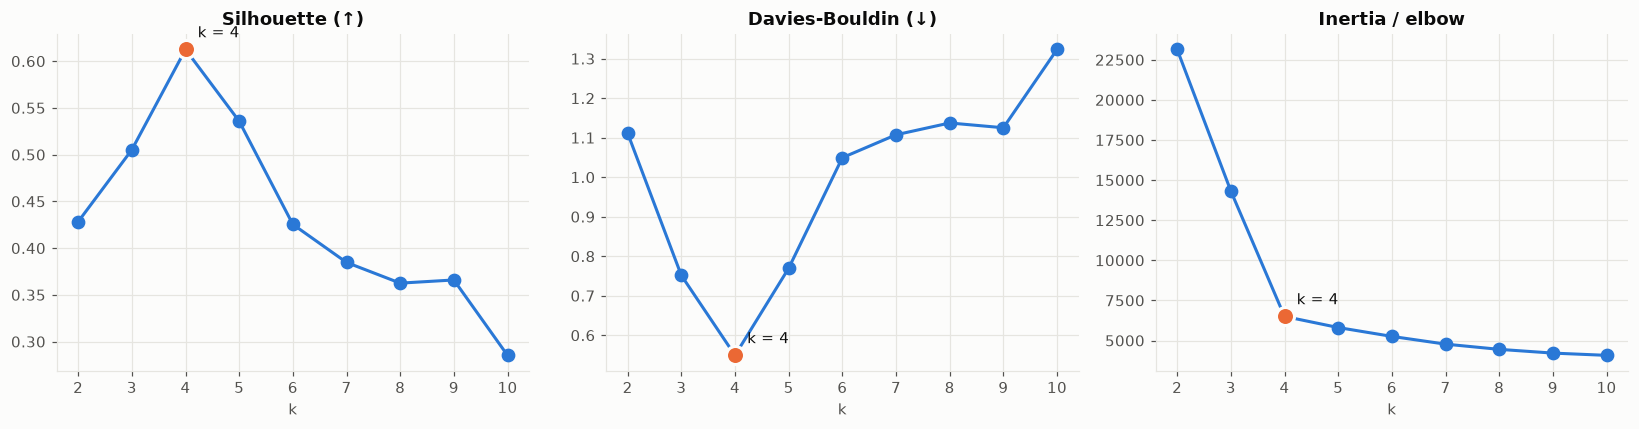

,silhouette,davies_bouldin,inertia
k,,,
2,0.43,1.11,"23,141.68"
3,0.51,0.75,"14,319.20"
4,0.61,0.55,"6,500.77"
5,0.54,0.77,"5,808.90"
6,0.42,1.05,"5,255.98"
7,0.39,1.11,"4,774.08"
8,0.36,1.14,"4,448.82"
9,0.37,1.12,"4,215.08"
10,0.28,1.32,"4,074.98"


In [18]:
hasil_C = evaluasi_k(X)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kol, judul in zip(axes, ["silhouette", "davies_bouldin", "inertia"],
                          ["Silhouette (↑)", "Davies-Bouldin (↓)", "Inertia / elbow"]):
    ax.plot(hasil_C.index, hasil_C[kol], marker="o", markersize=8, color=SERI[0])
    ax.scatter([4], [hasil_C.loc[4, kol]], s=140, color=SERI[1], zorder=3, edgecolor=PERMUKAAN, linewidth=2)
    ax.annotate("k = 4", (4, hasil_C.loc[4, kol]), xytext=(8, 8), textcoords="offset points", color=TEKS)
    ax.set(title=judul, xlabel="k")
plt.tight_layout(); plt.show()
hasil_C.round(3)

In [19]:
# Stabilitas 1: seed berbeda -> apakah pembagiannya sama?
ref = KMeans(4, n_init=10, random_state=0).fit_predict(X)
ari_seed = [adjusted_rand_score(ref, KMeans(4, n_init=10, random_state=s).fit_predict(X)) for s in range(1, 11)]

# Stabilitas 2: latih di 80% data acak, prediksi seluruh data
ari_boot = []
for s in range(10):
    sub = np.random.RandomState(s).choice(len(X), int(0.8 * len(X)), replace=False)
    km = KMeans(4, n_init=10, random_state=s).fit(X[sub])
    ari_boot.append(adjusted_rand_score(ref, km.predict(X)))
print(f"ARI antar-seed      : rata-rata {np.mean(ari_seed):.3f} (min {np.min(ari_seed):.3f})")
print(f"ARI subsampel 80%   : rata-rata {np.mean(ari_boot):.3f} (min {np.min(ari_boot):.3f})")

ARI antar-seed      : rata-rata 1.000 (min 1.000)
ARI subsampel 80%   : rata-rata 1.000 (min 1.000)


**Alasan memilih k = 4**
1. **Silhouette tertinggi** (±0,61) dan **Davies-Bouldin terendah**. *Elbow* inertia juga menekuk di k = 4.
2. **Stabil**: ARI ≈ 1 antar-seed dan antar-subsampel. Segmen yang sama muncul lagi walau data atau inisialisasinya diubah.
3. **Masuk akal secara bisnis**: k = 5 hanya memecah pelanggan setia menjadi "datang kemarin" vs "datang minggu lalu",
   yang tidak membutuhkan promo berbeda. k = 3 menggabungkan pemburu promo dengan pembeli momen yang perilakunya
   bertolak belakang.
4. **Mudah dioperasikan**: 4 jenis promo masih realistis dijalankan oleh UMKM.

## 8. Model final & profil segmen

In [20]:
pipeline = Pipeline([
    ("fitur", ft.PembuatFitur()),
    ("skala", StandardScaler()),
    ("kmeans", KMeans(n_clusters=4, n_init=20, random_state=SEED)),
])
pipeline.fit(df[ft.KOLOM_INPUT])
label = pipeline.named_steps["kmeans"].labels_

profil_mentah = pd.DataFrame({
    "recency": df["hari_sejak_transaksi_terakhir"], "frekuensi": df["jumlah_transaksi_6bln"],
    "basket": df["basket_rp"], "promo": df["persen_pakai_promo"], "c": label,
}).groupby("c").median()
nama_cluster = seg.beri_nama_cluster(profil_mentah)
df["segmen"] = pd.Categorical(pd.Series(label).map(nama_cluster), categories=URUTAN_SEGMEN)
nama_cluster

{1: 'Mulai Menghilang',
 2: 'Pembeli Momen Spesial',
 0: 'Pelanggan Setia',
 3: 'Pemburu Promo Online'}

In [21]:
ringkas = df.groupby("segmen", observed=True).agg(
    jumlah=("id_pelanggan", "size"),
    recency_hari=("hari_sejak_transaksi_terakhir", "median"),
    transaksi_6bln=("jumlah_transaksi_6bln", "median"),
    total_belanja=("total_belanja_rp", "median"),
    basket=("basket_rp", "median"),
    promo_pct=("persen_pakai_promo", "median"),
    rating=("rating_rata", "median"),
    umur=("umur", "median"),
)
ringkas.insert(1, "porsi_%", (ringkas["jumlah"] / len(df) * 100).round(1))
ringkas["kontribusi_omzet_%"] = (df.groupby("segmen", observed=True)["total_belanja_rp"].sum()
                                 / df["total_belanja_rp"].sum() * 100).round(1)
ringkas.style.format({"total_belanja": "Rp {:,.0f}", "basket": "Rp {:,.0f}", "porsi_%": "{:.1f}",
                      "kontribusi_omzet_%": "{:.1f}", "rating": "{:.1f}", "umur": "{:.0f}",
                      "recency_hari": "{:.0f}", "transaksi_6bln": "{:.0f}", "promo_pct": "{:.0f}"})

,jumlah,porsi_%,recency_hari,transaksi_6bln,total_belanja,basket,promo_pct,rating,umur,kontribusi_omzet_%
segmen,,,,,,,,,,
Pelanggan Setia,3019,30.2,5,28,"Rp 1,304,400","Rp 48,110",20,4.4,27,58.5
Pemburu Promo Online,2499,25.0,12,11,"Rp 337,600","Rp 31,743",82,4.4,27,12.5
Pembeli Momen Spesial,1501,15.0,30,4,"Rp 1,047,000","Rp 276,220",12,4.4,38,24.3
Mulai Menghilang,2981,29.8,110,3,"Rp 98,500","Rp 41,433",34,3.6,27,4.6


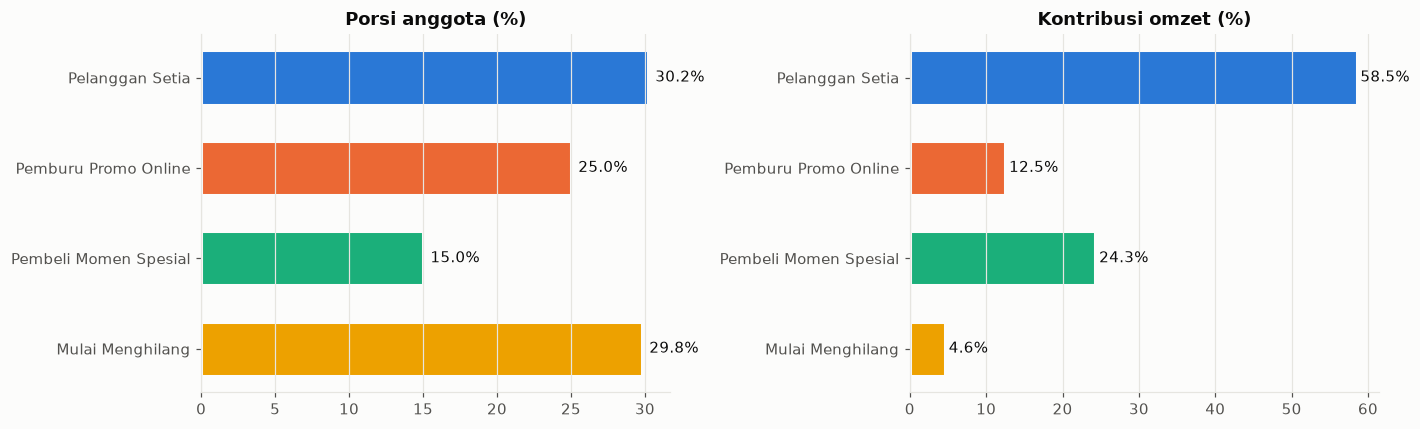

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, kol, judul in [(axes[0], "porsi_%", "Porsi anggota (%)"), (axes[1], "kontribusi_omzet_%", "Kontribusi omzet (%)")]:
    nilai = ringkas[kol]
    ax.barh(nilai.index.astype(str), nilai.values, color=[WARNA_SEGMEN[n] for n in nilai.index],
            height=0.6, edgecolor=PERMUKAAN, linewidth=2)
    for i, v in enumerate(nilai.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", color=TEKS, fontsize=10)
    ax.invert_yaxis(); ax.set_title(judul); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

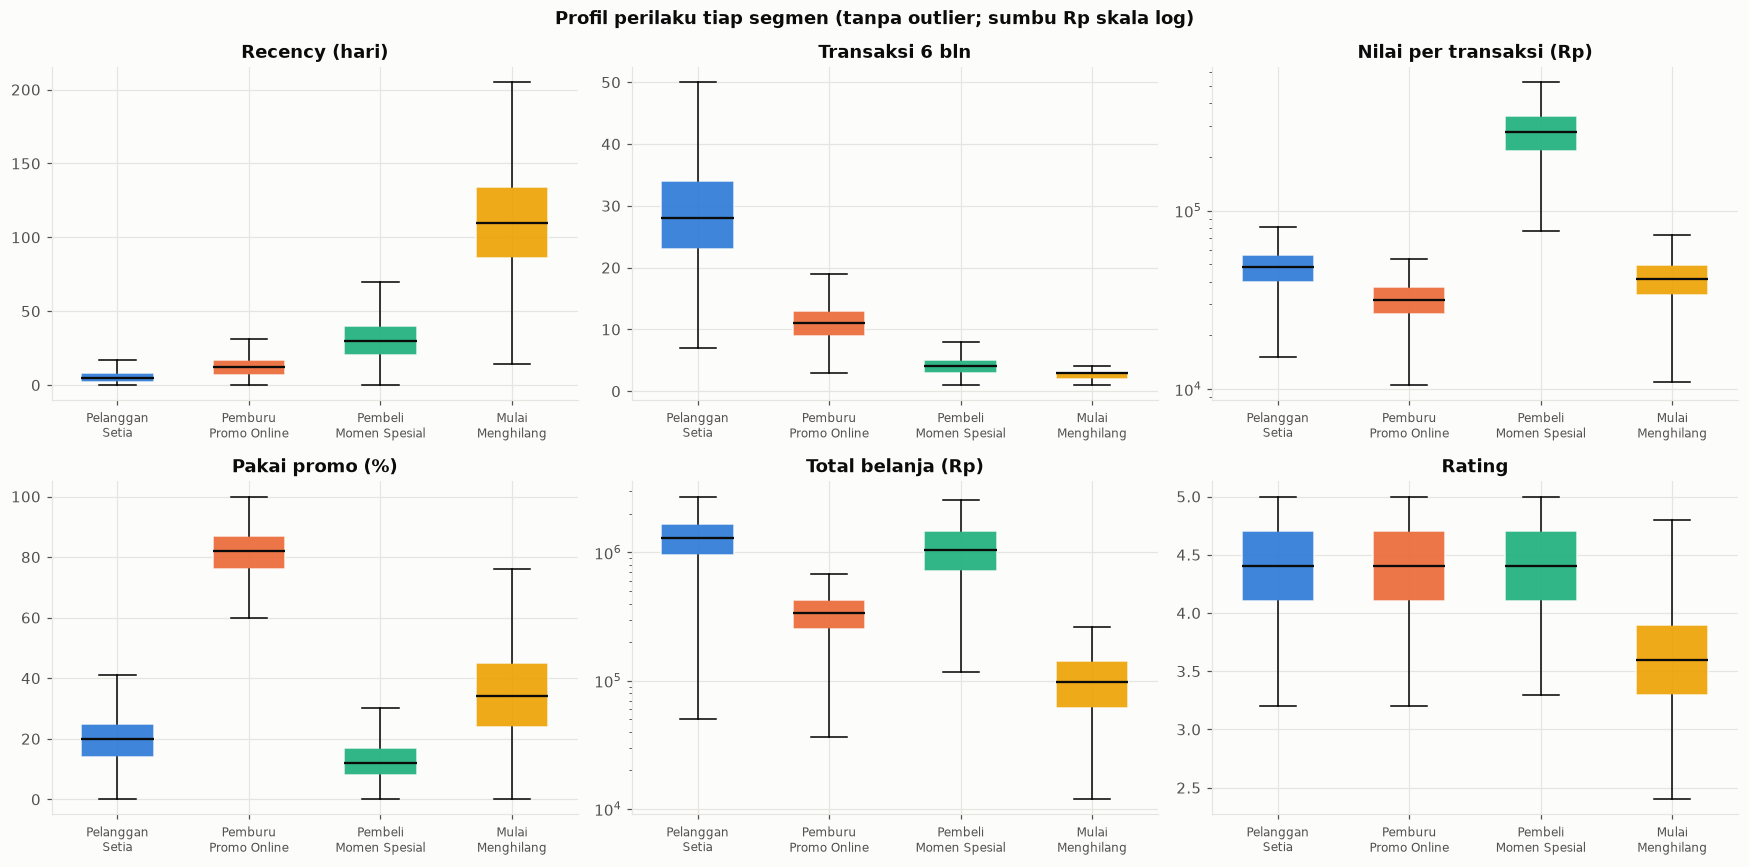

In [23]:
plot_cols = [("hari_sejak_transaksi_terakhir", "Recency (hari)"), ("jumlah_transaksi_6bln", "Transaksi 6 bln"),
             ("basket_rp", "Nilai per transaksi (Rp)"), ("persen_pakai_promo", "Pakai promo (%)"),
             ("total_belanja_rp", "Total belanja (Rp)"), ("rating_rata", "Rating")]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (c, judul) in zip(axes.flat, plot_cols):
    data = [df.loc[df["segmen"] == s, c].dropna() for s in URUTAN_SEGMEN]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False,
                    medianprops=dict(color=TEKS, linewidth=1.5))
    for patch, s in zip(bp["boxes"], URUTAN_SEGMEN):
        patch.set_facecolor(WARNA_SEGMEN[s]); patch.set_edgecolor(PERMUKAAN); patch.set_alpha(0.9)
    ax.set_xticks(range(1, 5), [s.replace(" ", "\n", 1) for s in URUTAN_SEGMEN], fontsize=8)
    ax.set_title(judul)
    if "Rp" in judul:
        ax.set_yscale("log")
fig.suptitle("Profil perilaku tiap segmen (tanpa outlier; sumbu Rp skala log)", fontweight="bold")
plt.tight_layout(); plt.show()

**Bacaan profil**
- **Pelanggan Setia** hanya ±30% anggota tetapi menyumbang **±58% omzet**. Segmen ini paling penting untuk dijaga.
- **Pembeli Momen Spesial** (15% anggota) menyumbang ±24% omzet dengan nilai per transaksi ±Rp 276 ribu, sekitar 6× segmen lain.
- **Pemburu Promo Online**: median 82% transaksinya memakai promo, dengan nilai per transaksi terkecil.
- **Mulai Menghilang** memberi **rating terendah** (median ±3,6 vs ±4,4). Ada indikasi pengalaman yang kurang
  memuaskan, jadi win-back sebaiknya disertai perbaikan layanan, bukan diskon saja.

In [24]:
# Cek bias anggota baru: apakah mereka menumpuk di segmen tertentu?
pd.crosstab(df["segmen"], np.where(df["masa_member_hari"] < 180, "member < 6 bln", "member >= 6 bln"),
            normalize="columns").mul(100).round(1)

col_0,member < 6 bln,member >= 6 bln
segmen,,
Pelanggan Setia,29.60,30.30
Pemburu Promo Online,26.20,24.70
Pembeli Momen Spesial,14.60,15.10
Mulai Menghilang,29.60,29.80


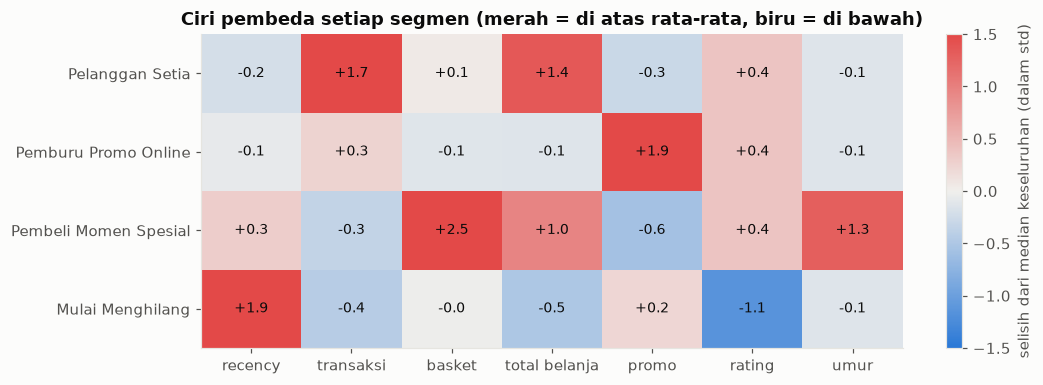

In [25]:
# Heatmap: seberapa jauh median tiap segmen dari median keseluruhan (z-score)
kol_z = ["hari_sejak_transaksi_terakhir", "jumlah_transaksi_6bln", "basket_rp", "total_belanja_rp",
         "persen_pakai_promo", "rating_rata", "umur"]
z = (df.groupby("segmen", observed=True)[kol_z].median() - df[kol_z].median()) / df[kol_z].std()
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(z, cmap=DIVERGING, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(kol_z)), ["recency", "transaksi", "basket", "total belanja", "promo", "rating", "umur"])
ax.set_yticks(range(len(z)), z.index)
ax.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.iloc[i, j]:+.1f}", ha="center", va="center", color=TEKS, fontsize=9)
fig.colorbar(im, ax=ax, label="selisih dari median keseluruhan (dalam std)")
ax.set_title("Ciri pembeda setiap segmen (merah = di atas rata-rata, biru = di bawah)")
plt.tight_layout(); plt.show()

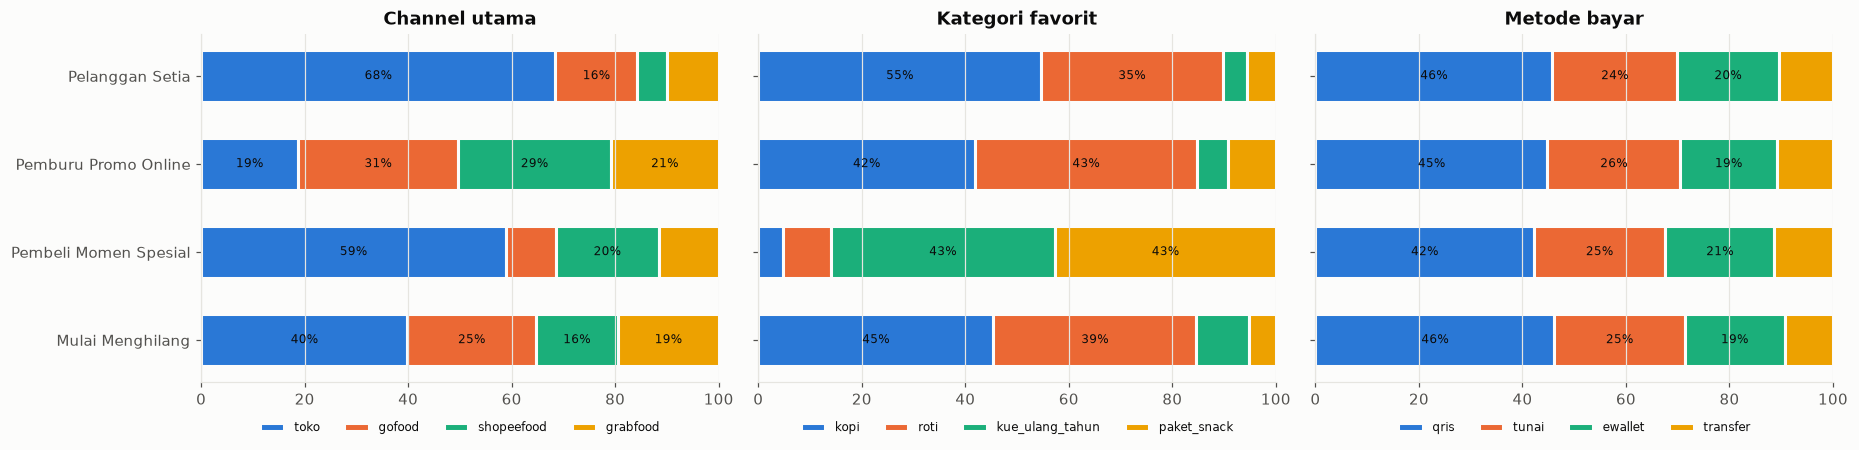

channel_utama,gofood,grabfood,shopeefood,toko
segmen,,,,
Pelanggan Setia,15.90,10.00,5.70,68.40
Pemburu Promo Online,31.00,20.90,29.50,18.70
Pembeli Momen Spesial,9.70,11.60,19.90,58.80
Mulai Menghilang,24.80,19.50,15.90,39.90


kategori_favorit,kopi,kue_ulang_tahun,paket_snack,roti
segmen,,,,
Pelanggan Setia,54.60,4.60,5.70,35.10
Pemburu Promo Online,41.80,5.90,9.30,43.00
Pembeli Momen Spesial,4.80,43.30,42.70,9.20
Mulai Menghilang,45.40,10.20,5.20,39.20


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, kol, judul in zip(axes, ["channel_utama", "kategori_favorit", "metode_bayar"],
                          ["Channel utama", "Kategori favorit", "Metode bayar"]):
    ct = pd.crosstab(df["segmen"], df[kol], normalize="index") * 100
    ct = ct[ct.mean().sort_values(ascending=False).index]
    kiri = np.zeros(len(ct))
    for warna, cat in zip(SERI, ct.columns):
        ax.barh(ct.index.astype(str), ct[cat], left=kiri, color=warna, height=0.6,
                edgecolor=PERMUKAAN, linewidth=2, label=cat)
        for i, v in enumerate(ct[cat]):
            if v >= 12:
                ax.text(kiri[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color=TEKS, fontsize=8)
        kiri += ct[cat].values
    ax.invert_yaxis(); ax.set_title(judul); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
    ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08))
    if ax is not axes[0]:
        ax.set_yticklabels([])
plt.tight_layout(); plt.show()

for kol in ["channel_utama", "kategori_favorit"]:
    display((pd.crosstab(df["segmen"], df[kol], normalize="index") * 100).round(1))

Variansi dijelaskan PC1+PC2: 0.83


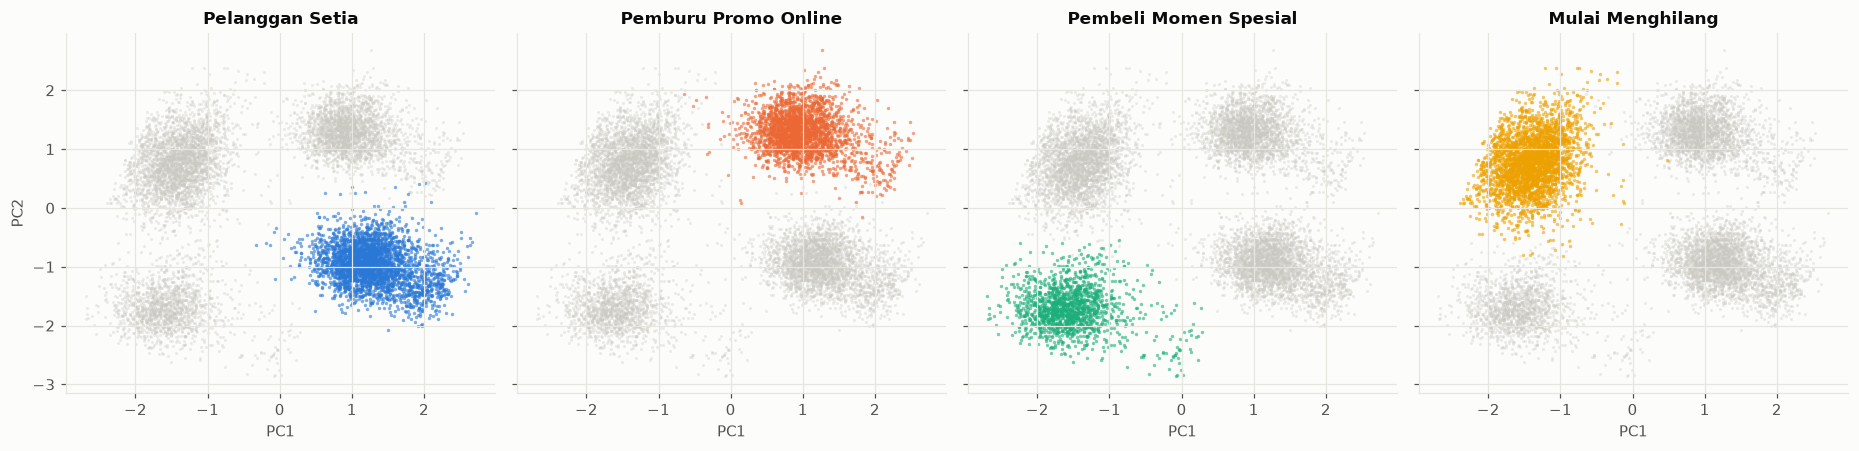

In [27]:
# Visualisasi 2D (PCA). Small multiples: 4 warna dalam satu scatter sulit dibedakan pembaca buta warna.
Xs = pipeline[:-1].transform(df[ft.KOLOM_INPUT])
pca = PCA(2, random_state=SEED).fit(Xs)
xy = pca.transform(Xs)
print("Variansi dijelaskan PC1+PC2:", pca.explained_variance_ratio_.sum().round(3))
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharex=True, sharey=True)
for ax, s in zip(axes, URUTAN_SEGMEN):
    m = (df["segmen"] == s).values
    ax.scatter(xy[~m, 0], xy[~m, 1], s=4, color=NETRAL, alpha=0.35, linewidths=0)
    ax.scatter(xy[m, 0], xy[m, 1], s=5, color=WARNA_SEGMEN[s], alpha=0.6, linewidths=0)
    ax.set_title(s, fontsize=11); ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [28]:
sil = silhouette_samples(Xs, label)
print("Silhouette rata-rata per segmen:")
print(pd.Series(sil, index=df.index).groupby(df["segmen"], observed=True).mean().round(3))

Silhouette rata-rata per segmen:
segmen
Pelanggan Setia         0.61
Pemburu Promo Online    0.62
Pembeli Momen Spesial   0.63
Mulai Menghilang        0.59
dtype: float64


## 9. Nama, profil, dan rekomendasi per segmen

Nama ditentukan dari profil median di atas (aturan pemetaan ada di `src/segmen.py`, sehingga nama
tetap konsisten walaupun nomor cluster K-Means berubah).

In [29]:
rekom = pd.DataFrame({
    "porsi_%": ringkas["porsi_%"],
    "profil": [seg.INFO_SEGMEN[s]["profil"] for s in ringkas.index],
    "rekomendasi_promo": [seg.INFO_SEGMEN[s]["promo"] for s in ringkas.index],
})
with pd.option_context("display.max_colwidth", None):
    display(rekom)

,porsi_%,profil,rekomendasi_promo
segmen,,,
Pelanggan Setia,30.20,"Sangat sering belanja (median ~28x/6 bln), baru saja datang, jarang memakai promo, mayoritas beli langsung di toko.","Program poin / member tier: hadiah non-diskon (gratis upgrade ukuran, akses menu baru lebih dulu, free item di transaksi ke-10). Hindari diskon besar, mereka sudah membeli dengan harga normal."
Pemburu Promo Online,25.00,"Belanja cukup rutin (~11x) dengan nilai kecil, hampir selalu memakai promo, dominan lewat aplikasi ojek online.","Promo bundling dengan minimum belanja (mis. beli 2 kopi + 1 roti hemat 15%) untuk menaikkan nilai per transaksi, serta voucher khusus ambil di toko atau pesan via aplikasi member agar tidak bergantung pada potongan ojol."
Pembeli Momen Spesial,15.00,"Jarang belanja (~4x) tetapi nilai per transaksi sangat besar; favorit kue ulang tahun & paket snack, usia lebih matang, hampir tidak butuh promo.","Pengingat personal menjelang ulang tahun/acara + layanan pre-order kue, dan paket snack box untuk kantor/arisan. Beri bonus (lilin, kartu ucapan, ongkir gratis), bukan diskon."
Mulai Menghilang,29.80,"Sudah lama tidak datang (median ~110 hari), frekuensi dan belanja rendah, dan memberi rating paling rendah (~3,6), sehingga ada indikasi pengalaman yang kurang memuaskan.","Kampanye win-back: satu voucher kuat berbatas waktu (mis. diskon 30% berlaku 7 hari) dengan pesan 'kami rindu kamu' + survei singkat 'apa yang bisa kami perbaiki?', ditambah menu baru sebagai alasan untuk kembali."


| Segmen | Siapa mereka | Satu tindakan | Kenapa cocok |
|---|---|---|---|
| **Pelanggan Setia** | sering, baru datang, promo rendah, beli di toko | program poin / tier dengan hadiah non-diskon | mereka sudah membayar harga normal; diskon hanya mengurangi margin. Yang perlu dijaga adalah rasa dihargai |
| **Pemburu Promo Online** | rutin, nominal kecil, promo ±80%, lewat ojol | bundling dengan minimum belanja + voucher ambil di toko | menaikkan nilai per transaksi dan memindahkan pesanan dari ojol (komisi tinggi) ke kanal sendiri |
| **Pembeli Momen Spesial** | jarang, nilai besar, kue/snack box, usia lebih matang | pengingat acara + pre-order + bonus layanan | kebutuhannya musiman; yang dibutuhkan adalah diingatkan pada waktu yang tepat, bukan potongan harga |
| **Mulai Menghilang** | sudah ±110 hari tidak datang | satu voucher win-back kuat yang berbatas waktu | diskon besar hanya tepat di sini, karena tujuannya mencegah pelanggan hilang dan batas waktu memaksa segera kembali |

## 10. Simpan artifact & uji prediksi pelanggan baru

Disimpan ke `artifacts/`:
- `model.joblib`: **pipeline lengkap** (pembuat fitur → StandardScaler → K-Means), jadi aplikasi cukup mengirim 4 angka mentah.
- `metadata.json`: versi model, fitur masukan, peta nomor cluster → nama segmen, profil & promo tiap segmen,
  batas masukan yang dianggap wajar, ambang jarak, metrik, dan versi library.

**Ambang jarak** menggantikan *threshold* pada model klasifikasi. Pelanggan yang jaraknya ke pusat segmen terdekat
melebihi persentil-99 data latih ditandai "di luar kebiasaan", supaya pemilik usaha tahu prediksinya kurang meyakinkan.

**Batas masukan** sengaja dibuat lebih longgar daripada rentang data latih (transaksi 1-56, belanja per transaksi
±Rp 10 ribu-555 ribu) agar pelanggan ekstrem tetapi mungkin tetap dijawab dan diberi tanda. Hanya nilai mustahil
yang ditolak (negatif, promo > 100%, belanja per transaksi < Rp 1.000).

In [30]:
import json, datetime, platform, sklearn

jarak_latih = pipeline.transform(df[ft.KOLOM_INPUT]).min(axis=1)

def ke_float(d):
    return {k: (None if pd.isna(v) else round(float(v), 2)) for k, v in d.items()}

metadata = {
    "versi_model": "1.0.0",
    "dibuat": str(datetime.date.today()),
    "tugas": "segmentasi pelanggan (clustering, unsupervised)",
    "algoritma": "StandardScaler + KMeans(k=4, n_init=20) pada log(recency), log(frekuensi), "
                 "log(belanja per transaksi), dan persen pakai promo",
    "fitur_input": ft.KOLOM_INPUT,
    "fitur_model": ft.FITUR_MODEL,
    "k": 4,
    "nama_cluster": {str(k): v for k, v in nama_cluster.items()},
    "ambang_jarak": round(float(np.percentile(jarak_latih, 99)), 4),
    "batas_input": {
        "jumlah_transaksi_6bln": [1, 500],
        "total_belanja_rp": [1_000, 100_000_000],
        "hari_sejak_transaksi_terakhir": [0, 365],
        "persen_pakai_promo": [0, 100],
        "belanja_per_transaksi": [1_000, 5_000_000],
    },
    "metrik": {
        "silhouette_baseline_kmeans_rfm_mentah": round(float(hasil_baseline["silhouette"].max()), 4),
        "k_terbaik_baseline": int(hasil_baseline["silhouette"].idxmax()),
        "silhouette_final": round(float(silhouette_score(Xs, label)), 4),
        "davies_bouldin_final": round(float(davies_bouldin_score(Xs, label)), 4),
        "ari_stabilitas_antar_seed": round(float(np.mean(ari_seed)), 4),
        "ari_stabilitas_subsampel_80": round(float(np.mean(ari_boot)), 4),
        "persen_pelanggan_silhouette_di_atas_0_5": round(float((sil > 0.5).mean() * 100), 1),
    },
    "segmen": {
        nama: {**seg.INFO_SEGMEN[nama], "median": ke_float(ringkas.loc[nama])}
        for nama in URUTAN_SEGMEN
    },
    "data_latih": {"sumber": "kasus/05-segmentasi-umkm/data/raw.csv", **log_bersih},
    "versi_library": {
        "python": platform.python_version(), "sklearn": sklearn.__version__,
        "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__,
    },
}

ART = ROOT / "artifacts"
ART.mkdir(exist_ok=True)
joblib.dump(pipeline, ART / "model.joblib")
(ART / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

(ROOT / "data").mkdir(exist_ok=True)
df.drop(columns=["basket_rp"]).to_csv(ROOT / "data" / "pelanggan_tersegmentasi.csv", index=False)
contoh = raw.drop_duplicates("id_pelanggan").sample(12, random_state=7)[["id_pelanggan"] + ft.KOLOM_INPUT]
contoh.to_csv(ROOT / "data" / "contoh_batch.csv", index=False)

print(json.dumps(metadata["metrik"], indent=2))
print("ambang_jarak:", metadata["ambang_jarak"])

{
  "silhouette_baseline_kmeans_rfm_mentah": 0.5538,
  "k_terbaik_baseline": 4,
  "silhouette_final": 0.6125,
  "davies_bouldin_final": 0.5491,
  "ari_stabilitas_antar_seed": 1.0,
  "ari_stabilitas_subsampel_80": 1.0,
  "persen_pelanggan_silhouette_di_atas_0_5": 88.3
}
ambang_jarak: 1.8382


In [31]:
# Uji seperti aplikasi: muat artifact dari disk lewat app/predictor.py
from app import predictor
predictor.load.cache_clear()

pelanggan_baru = [
    {"jumlah_transaksi_6bln": 32, "total_belanja_rp": 1_600_000, "hari_sejak_transaksi_terakhir": 3,   "persen_pakai_promo": 15},
    {"jumlah_transaksi_6bln": 12, "total_belanja_rp": "Rp 420.000", "hari_sejak_transaksi_terakhir": 9, "persen_pakai_promo": 85},
    {"jumlah_transaksi_6bln": 3,  "total_belanja_rp": 1_250_000, "hari_sejak_transaksi_terakhir": 40,  "persen_pakai_promo": 5},
    {"jumlah_transaksi_6bln": 2,  "total_belanja_rp": 70_000,    "hari_sejak_transaksi_terakhir": 140, "persen_pakai_promo": 40},
    {"jumlah_transaksi_6bln": 60, "total_belanja_rp": 9_000_000, "hari_sejak_transaksi_terakhir": 0,   "persen_pakai_promo": 0},
]
hasil = pd.DataFrame(predictor.predict_rows(pelanggan_baru))
pd.concat([pd.DataFrame(pelanggan_baru), hasil[["segmen", "jarak_ke_pusat", "di_luar_kebiasaan", "catatan"]]], axis=1)

,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,segmen,jarak_ke_pusat,di_luar_kebiasaan,catatan
0,32,1600000,3,15,Pelanggan Setia,0.31,False,[]
1,12,Rp 420.000,9,85,Pemburu Promo Online,0.25,False,[]
2,3,1250000,40,5,Pembeli Momen Spesial,0.76,False,[]
3,2,70000,140,40,Mulai Menghilang,0.36,False,[]
4,60,9000000,0,0,Pelanggan Setia,2.21,True,[Perilaku pelanggan ini jauh dari semua segmen...


In [32]:
# Masukan tidak wajar harus ditolak dengan pesan yang jelas, bukan membuat aplikasi berhenti
tidak_valid = [
    {"jumlah_transaksi_6bln": 0,  "total_belanja_rp": 50_000,  "hari_sejak_transaksi_terakhir": 10, "persen_pakai_promo": 20},
    {"jumlah_transaksi_6bln": 5,  "total_belanja_rp": 200_000, "hari_sejak_transaksi_terakhir": 10, "persen_pakai_promo": 150},
    {"jumlah_transaksi_6bln": 50, "total_belanja_rp": 10_000,  "hari_sejak_transaksi_terakhir": 10, "persen_pakai_promo": 20},
    {"jumlah_transaksi_6bln": 5,  "total_belanja_rp": "abc",   "hari_sejak_transaksi_terakhir": None, "persen_pakai_promo": 20},
]
for row in tidak_valid:
    try:
        predictor.predict_one(row)
        print("LOLOS (seharusnya ditolak):", row)
    except ValueError as e:
        print("Ditolak ->", e)

Ditolak -> jumlah_transaksi_6bln: harus di antara 1 dan 500 (diterima: 0)
Ditolak -> persen_pakai_promo: harus di antara 0 dan 100 (diterima: 150)
Ditolak -> total belanja ÷ jumlah transaksi = Rp 200 per transaksi, tidak masuk akal (harus Rp 1.000 - Rp 5.000.000)
Ditolak -> total_belanja_rp: wajib diisi dengan angka (diterima: 'abc'); hari_sejak_transaksi_terakhir: wajib diisi dengan angka (diterima: None)


In [33]:
# Konsistensi: artifact yang dimuat memberi segmen yang sama dengan hasil pelatihan
ulang = [h["segmen"] for h in predictor.predict_rows(df[ft.KOLOM_INPUT].to_dict("records"))]
print("Kecocokan dengan label latih:", (np.array(ulang) == df["segmen"].astype(str).values).mean())

Kecocokan dengan label latih: 1.0


## 11. Keterbatasan & langkah lanjut

- **Anggota baru (< 6 bulan)** ternyata tersebar dengan proporsi yang sama dengan anggota lama (cek di bagian 8),
  jadi tidak terlihat bias. Meski begitu, `tanggal_daftar` tetap perlu diverifikasi ke klien.
- **±280 tanggal daftar tidak konsisten** dengan recency. Perlu ditanyakan ke klien.
- Segmen adalah potret Juni 2026. Pelanggan bisa berpindah segmen, jadi model sebaiknya dijalankan ulang
  setiap bulan dan efek promo diukur (A/B test per segmen).
- Aplikasi: `app/ui/streamlit_app.py` (Streamlit) dan `app/api/main.py` (FastAPI) memakai artifact ini.